# 1. Análise exploratória -- Detecção de Diabetes
Objetivo: classificar pacientes em **controle (0)** ou **diabetes (1)** a partir de dados clínicos.
Métricas da competição: precisão, recall de cada classe e **F1-macro**.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Lê os arquivos da competição
treino = pd.read_csv('kaggle-training set/kaggle-training set/train.csv')
teste = pd.read_csv('kaggle-test/kaggle-test/test.csv')

print('Tamanho do treino:', treino.shape)
print('Tamanho do teste:', teste.shape)
treino.head()

Tamanho do treino: (540, 21)
Tamanho do teste: (312, 20)


,id,PATIENT_CODE,EXAM_DATE,COLLECTION_SITE,LAB_DEVICE,STUDY_PROTOCOL,GENDER,AGE,BIRTH_YEAR,HEIGHT,...,BLOOD_PRESSURE,BLOOD_TYPE,SMOKER,PHYSICAL_ACTIVITY,FAMILY_HISTORY,GLUCOSE,HEMOGLOBIN,TRIGLYCERIDES,SODIUM,class
0,4,PT-E1A661,2018-02-23,SITE-003,FTIR-A,T2D-SPEC-v1,MALE,34.0,1984.0,170,...,113/87,O+,never,light,No,95.0,9.2,NaN,138.0,1
1,5,PT-D491C5,Jan 19 2021,SITE-004,FTIR-A,T2D-SPEC-v1,f,59.0,1962.0,161,...,114 / 75,B+,former,Sedentary,YES,120.0,8.5,171.0,137.0,1
2,6,PT-3DE493,17/02/2020,SITE-025,FTIR-A,T2D-SPEC-v1,FEMALE,44.0,1975.0,159,...,?,O+,NaN,Moderate,Não,NaN,5.3,159.0,138.0,0
3,7,PT-8D2D8E,19/05/2018,SITE-016,FTIR-A,T2D-SPEC-v1,MALE,49.0,1968.0,1.66,...,95/63,O-,never,NaN,No,NaN,6.4,281.0,142.0,0
4,8,PT-0F34CC,2020-04-05,SITE-001,FTIR-A,T2D-SPEC-v1,MALE,58.0,1961.0,1.66,...,115/83,O-,NaN,Light,YES,110.0,NaN,109.0,139.0,0


## 1.1 Classes e valores ausentes

In [2]:
# Quantos pacientes de cada classe (0 = controle, 1 = diabetes)
print(treino['class'].value_counts())

# Porcentagem de valores ausentes em cada coluna (as 10 maiores)
porcentagem_ausente = treino.isna().mean() * 100
porcentagem_ausente.sort_values(ascending=False).head(10).round(1)

class
1    281
0    259
Name: count, dtype: int64


SMOKER               32.8
HEMOGLOBIN           23.0
GLUCOSE              11.3
TRIGLYCERIDES         8.5
HEIGHT                6.3
PHYSICAL_ACTIVITY     4.8
BLOOD_PRESSURE        4.3
BLOOD_TYPE            3.9
FAMILY_HISTORY        3.5
WEIGHT                2.4
dtype: float64

## 1.2 Dados "sujos": a mesma informação escrita de vários jeitos

In [3]:
# A mesma informação escrita de jeitos diferentes
for coluna in ['GENDER', 'PHYSICAL_ACTIVITY', 'FAMILY_HISTORY']:
    print(coluna)
    print(treino[coluna].value_counts().to_dict())
    print()

print('Exemplos de pressão arterial:', treino['BLOOD_PRESSURE'].sample(8, random_state=3).tolist())
print('Exemplos de data do exame:', treino['EXAM_DATE'].sample(6, random_state=1).tolist())

GENDER
{'FEMALE': 305, 'MALE': 173, 'F': 11, 'f': 9, ' MALE': 8, 'Female': 7, 'male': 5, 'female': 5, 'm': 4, 'M': 3, 'Male': 2, 'FEMALE ': 2}

PHYSICAL_ACTIVITY
{'Light': 157, 'Sedentary': 149, 'Moderate': 99, 'Intense': 39, 'LIGHT': 11, 'Sedentary ': 10, 'light': 7, 'sedentary': 6, 'SEDENTARY': 6, 'Sedentry': 5, 'Ligth': 5, 'INTENSE': 4, 'moderate': 4, ' Moderate': 3, 'intense': 3, 'MODERATE': 3, 'Intensive': 2, 'Moderat': 1}

FAMILY_HISTORY
{'No': 256, 'Yes': 116, 'Unknown': 33, 'yes': 15, '0': 15, 'NO': 15, 'no': 13, 'Não': 12, 'N': 12, 'YES': 11, '1': 8, 'Sim': 8, 'Y': 7}

Exemplos de pressão arterial: ['120/86', '90/67', '122/82', '104/68', '127/87', '103/73', '105/63', '145/88']
Exemplos de data do exame: ['2019-07-05', 'Jan 5 2021', '17/05/2019', '2019-07-05', '2019-08-24', '2021-10-27']


## 1.3 Unidades misturadas
Glicose em mg/dL **e** mmol/L, HbA1c em % **e** mmol/mol, peso em kg **e** libras — por isso os histogramas têm "dois grupos".

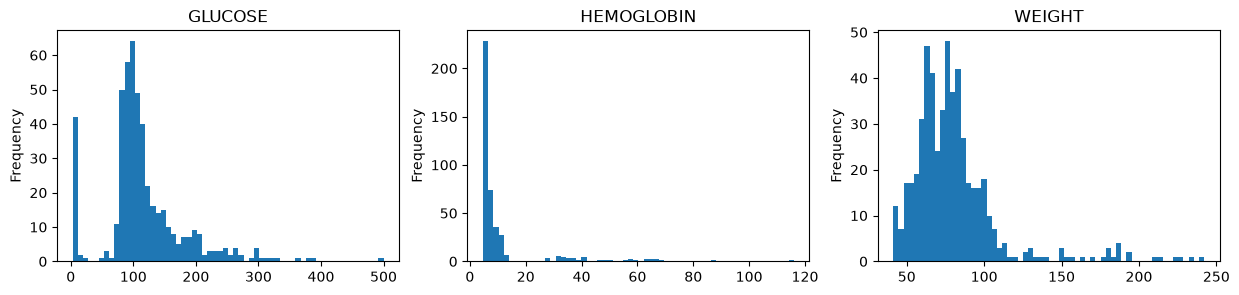

Glicose em mmol/L (valor < 30): 45
HbA1c em mmol/mol (valor > 20): 44
Altura em metros (valor < 3): 107
Peso em libras (valor > 130): 30
Idade inválida (0, -1 ou 999): 6


In [4]:
# Histogramas: valores em outra unidade aparecem como um "segundo grupo"
figura, eixos = plt.subplots(1, 3, figsize=(15, 3))
treino['GLUCOSE'].plot.hist(bins=60, ax=eixos[0], title='GLUCOSE')
treino['HEMOGLOBIN'].plot.hist(bins=60, ax=eixos[1], title='HEMOGLOBIN')
treino['WEIGHT'].plot.hist(bins=60, ax=eixos[2], title='WEIGHT')
plt.show()

# Quantos valores de cada problema de unidade
altura = pd.to_numeric(treino['HEIGHT'].str.replace(',', '.'))
print('Glicose em mmol/L (valor < 30):', (treino['GLUCOSE'] < 30).sum())
print('HbA1c em mmol/mol (valor > 20):', (treino['HEMOGLOBIN'] > 20).sum())
print('Altura em metros (valor < 3):', (altura < 3).sum())
print('Peso em libras (valor > 130):', (treino['WEIGHT'] > 130).sum())
print('Idade inválida (0, -1 ou 999):', treino['AGE'].isin([0, -1, 999]).sum())

## 1.4 Pacientes duplicados e colunas constantes

In [5]:
# Pacientes que aparecem mais de uma vez
duplicados = treino['PATIENT_CODE'].duplicated(keep=False)
print('Linhas de pacientes duplicados no treino:', duplicados.sum())
print('Pacientes do treino que também estão no teste:', treino['PATIENT_CODE'].isin(teste['PATIENT_CODE']).sum())

# Quantos valores diferentes existem nas colunas de protocolo e aparelho
treino[['STUDY_PROTOCOL', 'LAB_DEVICE']].nunique()

Linhas de pacientes duplicados no treino: 40
Pacientes do treino que também estão no teste: 0


STUDY_PROTOCOL    1
LAB_DEVICE        2
dtype: int64

## Conclusões
- É preciso **padronizar categorias**, **converter unidades** e **corrigir idades inválidas** (recalculadas pelo ano de nascimento).
- 20 pacientes aparecem duas vezes no treino → a validação será **agrupada por paciente** (`StratifiedGroupKFold`), senão o mesmo paciente cairia no treino e na validação.
- `STUDY_PROTOCOL` é constante e `LAB_DEVICE` quase constante → descartadas.